In [1]:
from sgt import SGT

import numpy as np
import pandas as pd
from itertools import chain
from itertools import product as iterproduct
import warnings

import pickle

########
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from keras.datasets import imdb
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Activation
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Embedding
from tensorflow.keras.preprocessing import sequence

from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedKFold
import sklearn.metrics
import time

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

import matplotlib.pyplot as plt
%matplotlib inline

np.random.seed(7) # fix random seed for reproducibility


In [2]:
df_train = pd.read_csv('TrainDataSet.csv',low_memory=False)
#df_train['S-Protein'] = df_train['S-Protein'].astype(np.float32)
df_train.dtypes

Identifier         object
S-Protein          object
Classification     object
Unnamed: 3        float64
dtype: object

In [3]:
df_train = df_train.drop(columns=['Unnamed: 3'])
list(df_train.columns)

['Identifier', 'S-Protein', 'Classification']

In [4]:
df_train=df_train.dropna()
df_train.shape

(104, 3)

In [5]:
df_train = df_train.replace('\n','', regex=True)
df_train['S-Protein'] = df_train['S-Protein'].str.strip(r'\\r')
print (df_train)

      Identifier                                          S-Protein  \
0    NC_045512.2  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
1       MZ437368  MFVFLVLLPLVSSQCVNLRTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
2       OM570262  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
3       QHR84449  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
4     QIX07431.1  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
..           ...                                                ...   
99    UST22952.1  MFVFLVLLPLVSSQCVNLITRTQSYTNSFTRGVYYPDKVFRSSVLH...   
100   QQV24132.1  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
101   QQV24885.1  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
102   QQV24803.1  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
103   QQV26579.1  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   

    Classification  
0          Regular  
1          Concern  
2          Concern  
3          Regular  
4          Regular  
..             ...  


In [6]:
#df_train = df_train.set_index('Identifier')
df_train

,Identifier,S-Protein,Classification
0,NC_045512.2,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...,Regular
1,MZ437368,MFVFLVLLPLVSSQCVNLRTRTQLPPAYTNSFTRGVYYPDKVFRSS...,Concern
2,OM570262,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...,Concern
3,QHR84449,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...,Regular
4,QIX07431.1,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...,Regular
...,...,...,...
99,UST22952.1,MFVFLVLLPLVSSQCVNLITRTQSYTNSFTRGVYYPDKVFRSSVLH...,Regular
100,QQV24132.1,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...,Regular
101,QQV24885.1,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...,Regular
102,QQV24803.1,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...,Regular


In [7]:
y = df_train['Classification']
encoder = LabelEncoder()
encoder.fit(y)
y = encoder.transform(y)
encoder_name_mapping_y = dict(zip(encoder.classes_, encoder.transform(encoder.classes_)))
print(encoder_name_mapping_y)

{'Concern': 0, 'Regular': 1}


In [8]:
y

array([1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1,
       0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1])

In [9]:
X = df_train['S-Protein'].apply(str)
def split(word): 
    return [char for char in word]
sequences = [split(x) for x in X]
print(sequences[0])

['M', 'F', 'V', 'F', 'L', 'V', 'L', 'L', 'P', 'L', 'V', 'S', 'S', 'Q', 'C', 'V', 'N', 'L', 'T', 'T', 'R', 'T', 'Q', 'L', 'P', 'P', 'A', 'Y', 'T', 'N', 'S', 'F', 'T', 'R', 'G', 'V', 'Y', 'Y', 'P', 'D', 'K', 'V', 'F', 'R', 'S', 'S', 'V', 'L', 'H', 'S', 'T', 'Q', 'D', 'L', 'F', 'L', 'P', 'F', 'F', 'S', 'N', 'V', 'T', 'W', 'F', 'H', 'A', 'I', 'H', 'V', 'S', 'G', 'T', 'N', 'G', 'T', 'K', 'R', 'F', 'D', 'N', 'P', 'V', 'L', 'P', 'F', 'N', 'D', 'G', 'V', 'Y', 'F', 'A', 'S', 'T', 'E', 'K', 'S', 'N', 'I', 'I', 'R', 'G', 'W', 'I', 'F', 'G', 'T', 'T', 'L', 'D', 'S', 'K', 'T', 'Q', 'S', 'L', 'L', 'I', 'V', 'N', 'N', 'A', 'T', 'N', 'V', 'V', 'I', 'K', 'V', 'C', 'E', 'F', 'Q', 'F', 'C', 'N', 'D', 'P', 'F', 'L', 'G', 'V', 'Y', 'Y', 'H', 'K', 'N', 'N', 'K', 'S', 'W', 'M', 'E', 'S', 'E', 'F', 'R', 'V', 'Y', 'S', 'S', 'A', 'N', 'N', 'C', 'T', 'F', 'E', 'Y', 'V', 'S', 'Q', 'P', 'F', 'L', 'M', 'D', 'L', 'E', 'G', 'K', 'Q', 'G', 'N', 'F', 'K', 'N', 'L', 'R', 'E', 'F', 'V', 'F', 'K', 'N', 'I', 'D', 'G', 'Y',

In [10]:
id = df_train['Identifier'].apply(str).tolist()
#corpus = pd.DataFrame(sequences)
corpus = pd.DataFrame(
    {'id': id,
     'sequence': sequences,
    })
corpus = corpus.dropna(axis=1)
corpus = corpus.reset_index(drop=True) 
corpus

,id,sequence
0,NC_045512.2,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
1,MZ437368,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
2,OM570262,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
3,QHR84449,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
4,QIX07431.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
...,...,...
99,UST22952.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
100,QQV24132.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
101,QQV24885.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
102,QQV24803.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."


In [11]:
embedding = corpus.set_index('id')
embedding

,sequence
id,
NC_045512.2,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
MZ437368,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
OM570262,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
QHR84449,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
QIX07431.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
...,...
UST22952.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
QQV24132.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
QQV24885.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."


In [12]:
# https://dmnfarrell.github.io/bioinformatics/mhclearning
# http://www.cryst.bbk.ac.uk/education/AminoAcid/the_twenty.html
# 1 letter code for 20 natural amino acids

codes = ['A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L',
         'M', 'N', 'P', 'Q', 'R', 'S', 'T', 'V', 'W', 'X','Y']

def create_dict(codes):
  char_dict = {}
  for index, val in enumerate(codes):
    char_dict[val] = index+1

  return char_dict

char_dict = create_dict(codes)

print(char_dict)
print("Dict Length:", len(char_dict))

{'A': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6, 'H': 7, 'I': 8, 'K': 9, 'L': 10, 'M': 11, 'N': 12, 'P': 13, 'Q': 14, 'R': 15, 'S': 16, 'T': 17, 'V': 18, 'W': 19, 'X': 20, 'Y': 21}
Dict Length: 21


In [13]:
def integer_encoding(data):
  """
  - Encodes code sequence to integer values.
 20 Amino Acids + 1 X for Unknown
  """
  
  encode_list = []
  for row in embedding['sequence'].values:
    row_encode = []
    for code in row:
      row_encode.append(char_dict.get(code, 0))
    encode_list.append(np.array(row_encode))
  
  return encode_list


In [14]:
train_encode = integer_encoding(embedding) 
train_encode

[array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ..., 

In [15]:
id = df_train['Identifier'].apply(str).tolist()
#corpus = pd.DataFrame(sequences)
corpus2 = pd.DataFrame(
    {'id': id,
     'sequence': train_encode,
    })
corpus2 = corpus2.dropna(axis=1)
corpus2 = corpus2.reset_index(drop=True)
corpus2 = corpus2.set_index('id')
corpus2

,sequence
id,
NC_045512.2,"[11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,..."
MZ437368,"[11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,..."
OM570262,"[11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,..."
QHR84449,"[11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,..."
QIX07431.1,"[11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,..."
...,...
UST22952.1,"[11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,..."
QQV24132.1,"[11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,..."
QQV24885.1,"[11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,..."


In [16]:
X = corpus2['sequence']
encoded_X = np.ndarray(shape=(len(X),), dtype=list)
for i in range(0,len(X)):
    encoded_X[i]=X.iloc[i]
X

id
NC_045512.2    [11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,...
MZ437368       [11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,...
OM570262       [11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,...
QHR84449       [11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,...
QIX07431.1     [11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,...
                                     ...                        
UST22952.1     [11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,...
QQV24132.1     [11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,...
QQV24885.1     [11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,...
QQV24803.1     [11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,...
QQV26579.1     [11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,...
Name: sequence, Length: 104, dtype: object

In [17]:
max_seq_length = 1273

In [18]:
encoded_X = tf.keras.preprocessing.sequence.pad_sequences(encoded_X, max_seq_length)

In [19]:
kfold = 5
random_state = 11

test_F1 = np.zeros(kfold)
time_k = np.zeros(kfold)

epochs = 100
batch_size = 10
skf = StratifiedKFold(n_splits=kfold, shuffle=True, random_state=random_state)
k = 0

for train_index, test_index in skf.split(encoded_X, y):
    X_train, X_test = encoded_X[train_index], encoded_X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    
    embedding_vecor_length = 32
    top_words=50
    model = Sequential()
    model.add(Embedding(top_words, embedding_vecor_length, input_length=max_seq_length))
    model.add(LSTM(32))
    model.add(Dense(1))
    model.add(Activation('sigmoid'))
    model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
    
    model.summary()
    
    start_time = time.time()
    history = model.fit(X_train, y_train,  validation_split=0.2, epochs=epochs, batch_size=batch_size, verbose=1)
    end_time=time.time()
    time_k[k]=end_time-start_time

    y_pred = model.predict(X_test).round().astype(int)
    y_train_pred=model.predict(X_train).round().astype(int)
    test_F1[k]=sklearn.metrics.f1_score(y_test, y_pred)
    k+=1

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 1273, 32)          1600      
                                                                 
 lstm (LSTM)                 (None, 32)                8320      
                                                                 
 dense (Dense)               (None, 1)                 33        
                                                                 
 activation (Activation)     (None, 1)                 0         
                                                                 
Total params: 9,953
Trainable params: 9,953
Non-trainable params: 0
_________________________________________________________________
Epoch 1/100
7/7 [==============================] - 3s 229ms/step - loss: 0.6839 - accuracy: 0.6818 - val_loss: 0.6852 - val_accuracy: 0.5882
Epoch 2/100
7/7 [============================

7/7 [==============================] - 1s 155ms/step - loss: 0.6480 - accuracy: 0.7273 - val_loss: 0.6560 - val_accuracy: 0.6471
Epoch 3/100
7/7 [==============================] - 1s 153ms/step - loss: 0.5977 - accuracy: 0.7273 - val_loss: 0.6618 - val_accuracy: 0.6471
Epoch 4/100
7/7 [==============================] - 1s 152ms/step - loss: 0.5898 - accuracy: 0.7273 - val_loss: 0.6836 - val_accuracy: 0.6471
Epoch 5/100
7/7 [==============================] - 1s 158ms/step - loss: 0.5983 - accuracy: 0.7273 - val_loss: 0.6685 - val_accuracy: 0.6471
Epoch 6/100
7/7 [==============================] - 1s 155ms/step - loss: 0.5898 - accuracy: 0.7273 - val_loss: 0.6686 - val_accuracy: 0.6471
Epoch 7/100
7/7 [==============================] - 1s 153ms/step - loss: 0.5880 - accuracy: 0.7273 - val_loss: 0.6704 - val_accuracy: 0.6471
Epoch 8/100
7/7 [==============================] - 1s 159ms/step - loss: 0.5866 - accuracy: 0.7273 - val_loss: 0.6636 - val_accuracy: 0.6471
Epoch 9/100
7/7 [========

Epoch 60/100
7/7 [==============================] - 1s 155ms/step - loss: 0.5869 - accuracy: 0.7273 - val_loss: 0.6664 - val_accuracy: 0.6471
Epoch 61/100
7/7 [==============================] - 1s 155ms/step - loss: 0.5871 - accuracy: 0.7273 - val_loss: 0.6653 - val_accuracy: 0.6471
Epoch 62/100
7/7 [==============================] - 1s 155ms/step - loss: 0.5876 - accuracy: 0.7273 - val_loss: 0.6674 - val_accuracy: 0.6471
Epoch 63/100
7/7 [==============================] - 1s 154ms/step - loss: 0.5865 - accuracy: 0.7273 - val_loss: 0.6614 - val_accuracy: 0.6471
Epoch 64/100
7/7 [==============================] - 1s 155ms/step - loss: 0.5863 - accuracy: 0.7273 - val_loss: 0.6614 - val_accuracy: 0.6471
Epoch 65/100
7/7 [==============================] - 1s 154ms/step - loss: 0.5864 - accuracy: 0.7273 - val_loss: 0.6624 - val_accuracy: 0.6471
Epoch 66/100
7/7 [==============================] - 1s 153ms/step - loss: 0.5866 - accuracy: 0.7273 - val_loss: 0.6690 - val_accuracy: 0.6471
Epoch 

Epoch 68/100
7/7 [==============================] - 1s 156ms/step - loss: 0.5728 - accuracy: 0.7424 - val_loss: 0.7222 - val_accuracy: 0.5882
Epoch 69/100
7/7 [==============================] - 1s 154ms/step - loss: 0.5739 - accuracy: 0.7424 - val_loss: 0.7380 - val_accuracy: 0.5882
Epoch 70/100
7/7 [==============================] - 1s 157ms/step - loss: 0.5737 - accuracy: 0.7424 - val_loss: 0.7463 - val_accuracy: 0.5882
Epoch 71/100
7/7 [==============================] - 1s 157ms/step - loss: 0.5757 - accuracy: 0.7424 - val_loss: 0.7231 - val_accuracy: 0.5882
Epoch 72/100
7/7 [==============================] - 1s 155ms/step - loss: 0.5717 - accuracy: 0.7424 - val_loss: 0.7219 - val_accuracy: 0.5882
Epoch 73/100
7/7 [==============================] - 1s 155ms/step - loss: 0.5721 - accuracy: 0.7424 - val_loss: 0.7252 - val_accuracy: 0.5882
Epoch 74/100
7/7 [==============================] - 1s 188ms/step - loss: 0.5711 - accuracy: 0.7424 - val_loss: 0.7294 - val_accuracy: 0.5882
Epoch 

Epoch 76/100
7/7 [==============================] - 1s 154ms/step - loss: 0.6027 - accuracy: 0.7121 - val_loss: 0.6066 - val_accuracy: 0.7059
Epoch 77/100
7/7 [==============================] - 1s 156ms/step - loss: 0.6021 - accuracy: 0.7121 - val_loss: 0.6058 - val_accuracy: 0.7059
Epoch 78/100
7/7 [==============================] - 1s 158ms/step - loss: 0.6004 - accuracy: 0.7121 - val_loss: 0.6058 - val_accuracy: 0.7059
Epoch 79/100
7/7 [==============================] - 1s 156ms/step - loss: 0.6009 - accuracy: 0.7121 - val_loss: 0.6059 - val_accuracy: 0.7059
Epoch 80/100
7/7 [==============================] - 1s 157ms/step - loss: 0.6008 - accuracy: 0.7121 - val_loss: 0.6059 - val_accuracy: 0.7059
Epoch 81/100
7/7 [==============================] - 1s 156ms/step - loss: 0.6008 - accuracy: 0.7121 - val_loss: 0.6058 - val_accuracy: 0.7059
Epoch 82/100
7/7 [==============================] - 1s 155ms/step - loss: 0.6011 - accuracy: 0.7121 - val_loss: 0.6062 - val_accuracy: 0.7059
Epoch 

Epoch 84/100
7/7 [==============================] - 1s 156ms/step - loss: 0.5674 - accuracy: 0.7463 - val_loss: 0.7440 - val_accuracy: 0.5882
Epoch 85/100
7/7 [==============================] - 1s 154ms/step - loss: 0.5676 - accuracy: 0.7463 - val_loss: 0.7370 - val_accuracy: 0.5882
Epoch 86/100
7/7 [==============================] - 1s 155ms/step - loss: 0.5708 - accuracy: 0.7463 - val_loss: 0.7308 - val_accuracy: 0.5882
Epoch 87/100
7/7 [==============================] - 1s 154ms/step - loss: 0.5667 - accuracy: 0.7463 - val_loss: 0.7415 - val_accuracy: 0.5882
Epoch 88/100
7/7 [==============================] - 1s 157ms/step - loss: 0.5670 - accuracy: 0.7463 - val_loss: 0.7394 - val_accuracy: 0.5882
Epoch 89/100
7/7 [==============================] - 1s 156ms/step - loss: 0.5674 - accuracy: 0.7463 - val_loss: 0.7488 - val_accuracy: 0.5882
Epoch 90/100
7/7 [==============================] - 1s 160ms/step - loss: 0.5675 - accuracy: 0.7463 - val_loss: 0.7399 - val_accuracy: 0.5882
Epoch 

In [20]:
print ('Average f1 score', np.mean(test_F1))
print ('Average Run time', np.mean(time_k))

Average f1 score 0.8313725490196078
Average Run time 109.29717216491699


In [21]:
from keras.models import load_model

model.save('my_lstm_model.h5')  # creates a HDF5 file 'my_lstm_model.h5'

print("model saved!!!")

model saved!!!


In [22]:
model.summary()

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_4 (Embedding)     (None, 1273, 32)          1600      
                                                                 
 lstm_4 (LSTM)               (None, 32)                8320      
                                                                 
 dense_4 (Dense)             (None, 1)                 33        
                                                                 
 activation_4 (Activation)   (None, 1)                 0         
                                                                 
Total params: 9,953
Trainable params: 9,953
Non-trainable params: 0
_________________________________________________________________


dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


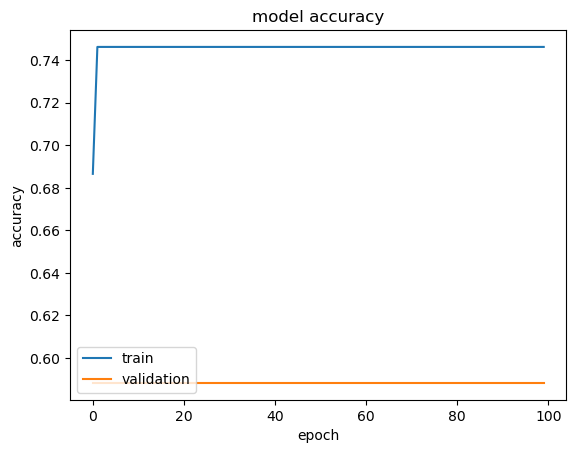

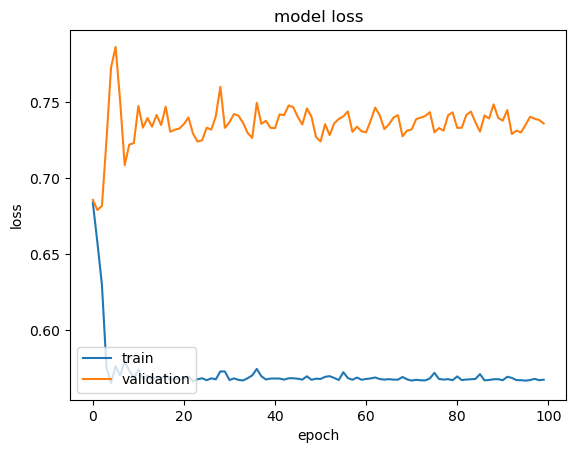

In [23]:
print(history.history.keys())
# summarize history for accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='lower left')
plt.show()
# summarize history for loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='lower left')
plt.show()

In [24]:
#Check with Test Data
df_test = pd.read_csv('TestDataSet.csv',low_memory=False)
df_test = df_test.drop(columns=['Unnamed: 3'])
df_test = df_test.replace('\n','', regex=True)
df_test['S-Protein'] = df_test['S-Protein'].str.strip(r'\\r')
X_test = df_test['S-Protein'].apply(str)
test_sequences = [split(x) for x in X_test]
 
identifier2=df_test['Identifier'].apply(str).tolist()
corpus_new = pd.DataFrame(
    {'id': identifier2,
     'sequence': test_sequences,
    })
corpus_new = corpus_new.dropna(axis=1)
corpus_new = corpus_new.reset_index(drop=True)
corpus_new = corpus_new.set_index('id')
corpus_new

,sequence
id,
OR575624.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
UJK14488.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
QTZ19244.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
WBQ65914.2,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
QZQ30931.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
QZQ31266.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
QZQ31201.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
QZQ31904.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
QZQ31816.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."


In [25]:
def integer_encoding(data):
  """
  - Encodes code sequence to integer values.
 20 Amino Acids + 1 X for Unknown
  """
  
  encode_list = []
  for row in corpus_new['sequence'].values:
    row_encode = []
    for code in row:
      row_encode.append(char_dict.get(code, 0))
    encode_list.append(np.array(row_encode))
  
  return encode_list

test_encode = integer_encoding(corpus_new) 
test_encode

[array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17])]

In [26]:
corpus_test = pd.DataFrame(
    {'id': identifier2,
     'sequence': test_encode,
    })
corpus_test = corpus_test.dropna(axis=1)
corpus_test = corpus_test.reset_index(drop=True)
corpus_test = corpus_test.set_index('id')
corpus_test

,sequence
id,
OR575624.1,"[11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,..."
UJK14488.1,"[11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,..."
QTZ19244.1,"[11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,..."
WBQ65914.2,"[11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,..."
QZQ30931.1,"[11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,..."
QZQ31266.1,"[11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,..."
QZQ31201.1,"[11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,..."
QZQ31904.1,"[11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,..."
QZQ31816.1,"[11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,..."


In [27]:
X = corpus_test['sequence']
encoded_X = np.ndarray(shape=(len(X),), dtype=list)
for i in range(0,len(X)):
    encoded_X[i]=X.iloc[i]
X

id
OR575624.1    [11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,...
UJK14488.1    [11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,...
QTZ19244.1    [11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,...
WBQ65914.2    [11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,...
QZQ30931.1    [11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,...
QZQ31266.1    [11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,...
QZQ31201.1    [11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,...
QZQ31904.1    [11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,...
QZQ31816.1    [11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,...
QZQ31673.1    [11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,...
QZQ31585.1    [11, 5, 18, 5, 10, 18, 10, 10, 13, 10, 18, 16,...
Name: sequence, dtype: object

In [28]:
X_test = tf.keras.preprocessing.sequence.pad_sequences(encoded_X, max_seq_length)

In [30]:
y_new = model.predict(X_test)
# show the inputs and predicted outputs
for i in range(len(y_new)):
 print("identifier=%s, Predicted=%s" % (id[i], y_new[i]))

1/1 [==============================] - 0s 43ms/step
identifier=NC_045512.2, Predicted=[0.7453229]
identifier=MZ437368, Predicted=[0.7453229]
identifier=OM570262, Predicted=[0.7453229]
identifier=QHR84449, Predicted=[0.7453229]
identifier=QIX07431.1, Predicted=[0.7453229]
identifier=UUT42029.1, Predicted=[0.7453229]
identifier=QTZ19280.1, Predicted=[0.74532294]
identifier=QTZ19268.1, Predicted=[0.74532294]
identifier=QIZ97051.1, Predicted=[0.74532294]
identifier=WEF91819.2, Predicted=[0.74532294]
identifier=WEF85329.2, Predicted=[0.74532294]
